# Rice Leaf Disease Detection using Transfer Learning (CNN)

**Goal:** classify rice leaf images into 3 major diseases: Bacterial Leaf Blight, Brown Spot and Leaf Smut.

**Dataset:** 119 images after removing 1 duplicate (originally 120, 40 per class).

**Approach:** the dataset is small, so we use transfer learning with a pre-trained MobileNetV2, plus data augmentation, and compare it with a CNN trained from scratch.

In [1]:
# import libraries

In [2]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
# Setup:

import os, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA_DIR = r"C:\Users\USER\Datamites Projects\Project 2\PRCP-1001-RiceLeaf\Data"
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

label
Bacterial leaf blight    40
Brown spot               40
Leaf smut                40
Name: count, dtype: int64


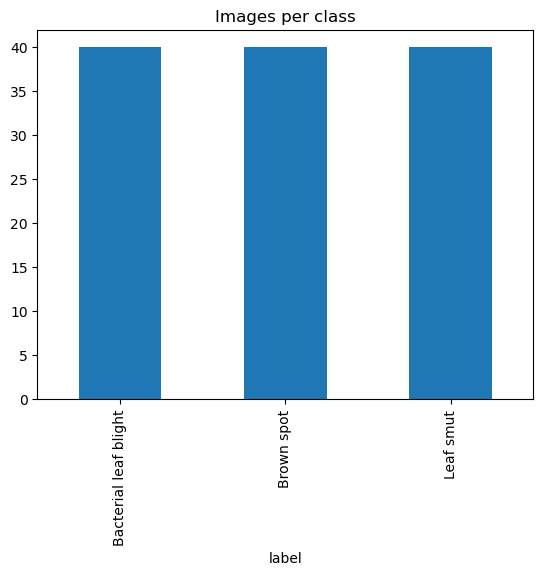

In [4]:
# EDA:

rows = []
for cls in os.listdir(DATA_DIR):
    for f in os.listdir(os.path.join(DATA_DIR, cls)):
        rows.append({"filepath": os.path.join(DATA_DIR, cls, f), "label": cls})
df = pd.DataFrame(rows)

print(df["label"].value_counts())
df["label"].value_counts().plot(kind="bar", title="Images per class")
plt.show()

In [5]:
# Remove duplicates:

df["hash"] = df["filepath"].apply(lambda p: hashlib.md5(open(p, "rb").read()).hexdigest())
print("Duplicates:", df["hash"].duplicated().sum())
df = df.drop_duplicates("hash").reset_index(drop=True)

Duplicates: 1


             width      height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000
                       brightness  pixel_std
label                                       
Bacterial leaf blight    0.699734   0.270619
Brown spot               0.663230   0.277093
Leaf smut                0.658090   0.262418


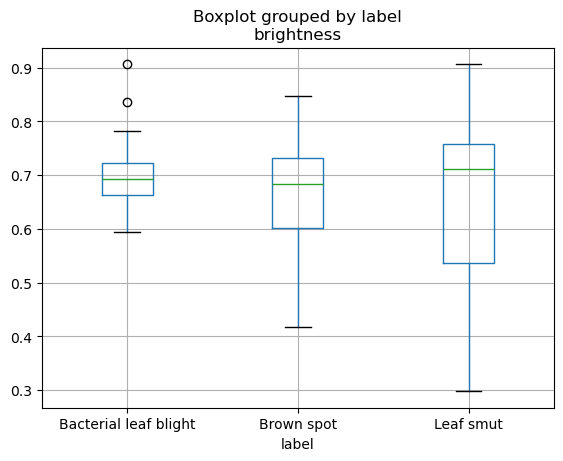

In [6]:
# Image size and pixel statistics:

def get_stats(path):
    img = Image.open(path).convert("RGB")
    arr = np.array(img) / 255.0
    return pd.Series({"width": img.width, "height": img.height,
                      "brightness": arr.mean(), "pixel_std": arr.std()})

df = pd.concat([df, df["filepath"].apply(get_stats)], axis=1)

print(df[["width", "height"]].describe())
print(df.groupby("label")[["brightness", "pixel_std"]].mean())
df.boxplot(column="brightness", by="label"); plt.show()

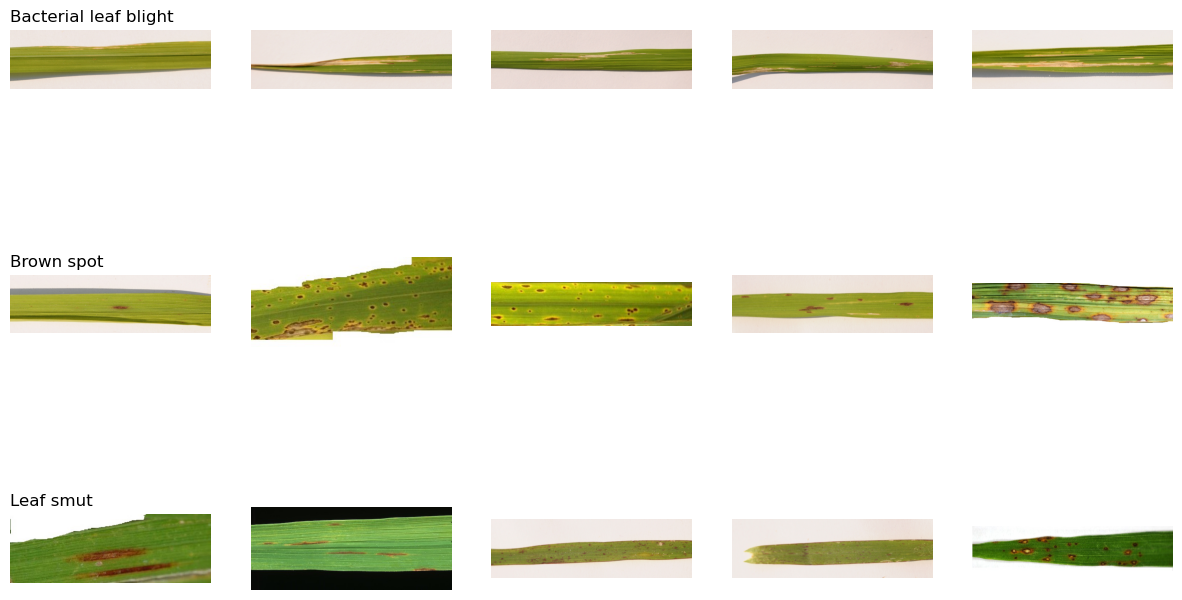

In [7]:
#Sample images:

classes = sorted(df["label"].unique())
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for i, c in enumerate(classes):
    paths = df[df.label == c]["filepath"].sample(5, random_state=SEED)
    for j, p in enumerate(paths):
        axes[i, j].imshow(Image.open(p)); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left")
plt.show()

## EDA Observations

- **Class balance:** the classes are balanced (about 40 images each), so no class weighting or resampling is needed.
- **Duplicates:** 1 duplicate image (Leaf smut) was found and removed, so the same image cannot appear in both training and test sets.
- **Image size:** *[write what your width/height describe() shows]*. All images are resized to 224x224 for MobileNetV2.
- **Background and lighting:** all images are lab-style photos with a plain black background and a centred leaf. Brightness is consistent across classes, which is good for training but means the model is untested on field photos.
- **Visual similarity:** Brown spot and Leaf smut lesions look alike (small brown marks on green leaf), so these two are the most likely to be confused.

In [8]:
# Train, Validation and test split:

train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)

print(len(train_df), len(val_df), len(test_df))

83 18 18


## Data Split

A stratified 70/15/15 split gives **83 training, 18 validation and 18 test images**, with equal classes (6 per class) in validation and test. The test set is never used during training or early stopping, so the test results are an unbiased estimate. The seed (42) makes the split reproducible.

In [9]:
# Data Generators:

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Augmentation settings defined once and reused
aug = dict(rotation_range=20, zoom_range=0.15,
           width_shift_range=0.1, height_shift_range=0.1,
           horizontal_flip=True, vertical_flip=True,
           brightness_range=(0.8, 1.2))

train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input, **aug)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)  # no augmentation

args = dict(x_col="filepath", y_col="label", target_size=IMG_SIZE,
            class_mode="categorical", batch_size=BATCH_SIZE)

train_gen = train_datagen.flow_from_dataframe(train_df, shuffle=True, seed=SEED, **args)
val_gen = eval_datagen.flow_from_dataframe(val_df, shuffle=False, **args)
test_gen = eval_datagen.flow_from_dataframe(test_df, shuffle=False, **args)

Found 83 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.
Found 18 validated image filenames belonging to 3 classes.


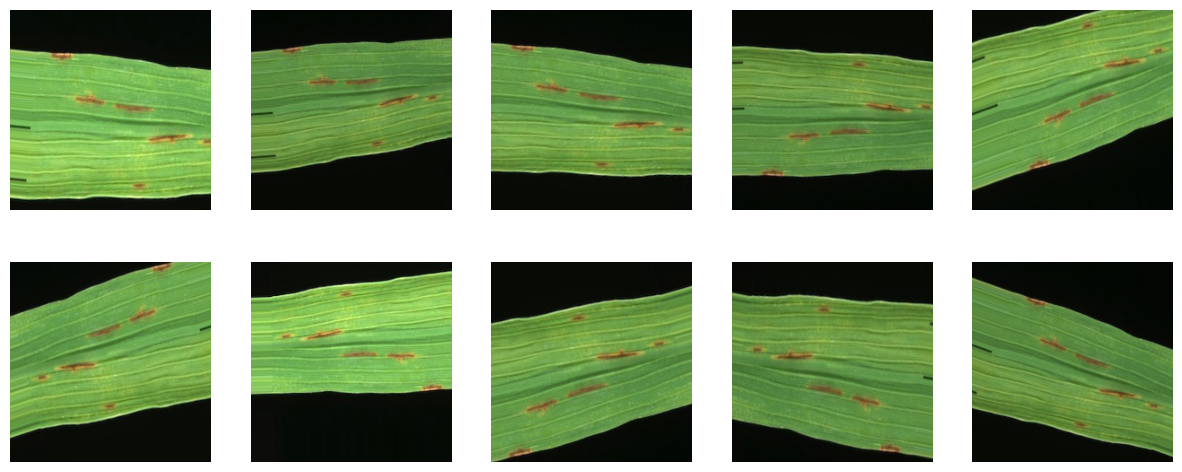

In [10]:
# Augmentation preview:

sample = np.array(Image.open(train_df.iloc[0]["filepath"]).convert("RGB").resize(IMG_SIZE))[None]
viz = ImageDataGenerator(**aug).flow(sample, batch_size=1)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax in axes.flat:
    ax.imshow(next(viz)[0].astype("uint8")); ax.axis("off")
plt.show()

## Augmentation Choices

Augmentation is applied to **training data only**. Validation and test images are only preprocessed, so the metrics reflect real, unmodified images.

| Technique | Setting | Reason |
|---|---|---|
| Rotation | ±20° | Leaves have no fixed orientation in photos |
| Horizontal and vertical flip | on | A mirrored leaf is still a valid leaf |
| Zoom | 0.15 | Camera distance varies |
| Width/height shift | 0.1 | Framing varies, but small so lesions are not cropped out |
| Brightness | 0.8 to 1.2 | Simulates sunlight and shadow differences |

The preview shows lesions remain visible after augmentation. Pixels are scaled with MobileNetV2's own `preprocess_input` (range -1 to 1), which matches how the pre-trained weights were trained.

In [11]:
# Models:

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [12]:
# MobileNetV2:

base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False

mobilenet_model = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax"),
])
mobilenet_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
mobilenet_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          81,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
# Baseline CNN:

baseline_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax"),
])
baseline_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

## Model Design

| Choice | Reason |
|---|---|
| Frozen MobileNetV2 base | With only 83 training images, retraining 2M+ parameters would overfit. Only about 82K parameters (the new head) are trained |
| GlobalAveragePooling2D | Far fewer parameters than Flatten, lowering overfitting risk |
| Dense(64) + Dropout(0.5) | Small classification head with regularisation |
| Baseline CNN (from scratch) | Shows how much transfer learning actually helps |
| EarlyStopping + ReduceLROnPlateau | Stops when validation loss stops improving and lowers the learning rate on plateaus |

In [14]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

In [15]:
# Train and evaluate both models:

history_mobilenet = mobilenet_model.fit(
    train_gen, validation_data=val_gen, epochs=30, callbacks=callbacks)

history_baseline = baseline_model.fit(
    train_gen, validation_data=val_gen, epochs=30, callbacks=callbacks)

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.3735 - loss: 1.3510 - val_accuracy: 0.7778 - val_loss: 0.6255 - learning_rate: 0.0010
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 704ms/step - accuracy: 0.6386 - loss: 0.7780 - val_accuracy: 0.7778 - val_loss: 0.4964 - learning_rate: 0.0010
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 646ms/step - accuracy: 0.7349 - loss: 0.6254 - val_accuracy: 0.7778 - val_loss: 0.4721 - learning_rate: 0.0010
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 880ms/step - accuracy: 0.7831 - loss: 0.5524 - val_accuracy: 0.7778 - val_loss: 0.4902 - learning_rate: 0.0010
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 738ms/step - accuracy: 0.7349 - loss: 0.6383 - val_accuracy: 0.7778 - val_loss: 0.4947 - learning_rate: 0.0010
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 774ms/step - accuracy: 0.8434 - loss: 0.4584 - val_accuracy: 0.8333 - val_loss: 0.4479 - learning_rate: 5.0000e-04
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 790ms/step - accuracy: 0.8916 - loss: 0.3337 - val_accuracy

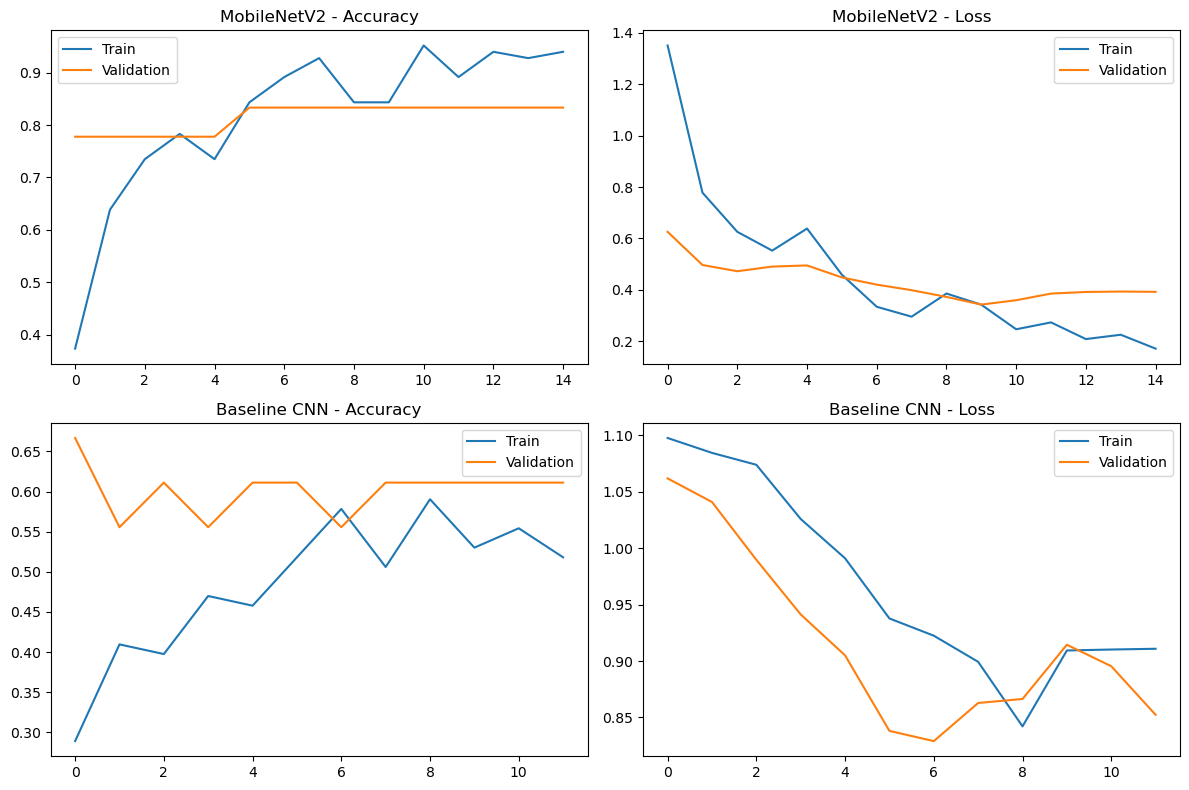

In [16]:
# Training Curves:

histories = {"MobileNetV2": history_mobilenet, "Baseline CNN": history_baseline}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, h) in enumerate(histories.items()):
    axes[row, 0].plot(h.history["accuracy"], label="Train")
    axes[row, 0].plot(h.history["val_accuracy"], label="Validation")
    axes[row, 0].set_title(f"{name} - Accuracy"); axes[row, 0].legend()

    axes[row, 1].plot(h.history["loss"], label="Train")
    axes[row, 1].plot(h.history["val_loss"], label="Validation")
    axes[row, 1].set_title(f"{name} - Loss"); axes[row, 1].legend()
plt.tight_layout(); plt.show()

## Training Curve Observations

- **MobileNetV2:** accuracy rises quickly and validation accuracy follows training accuracy closely, so overfitting is mild.
- **Baseline CNN:** both training and validation accuracy stay low. The model is **underfitting**: a small CNN cannot learn useful features from 83 images.
- Validation curves are jumpy because the validation set has only 18 images (one image is about 5.6%).

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 2s/step

===== MobileNetV2 =====
                       precision    recall  f1-score   support

Bacterial leaf blight       0.86      1.00      0.92         6
           Brown spot       0.83      0.83      0.83         6
            Leaf smut       1.00      0.83      0.91         6

             accuracy                           0.89        18
            macro avg       0.90      0.89      0.89        18
         weighted avg       0.90      0.89      0.89        18



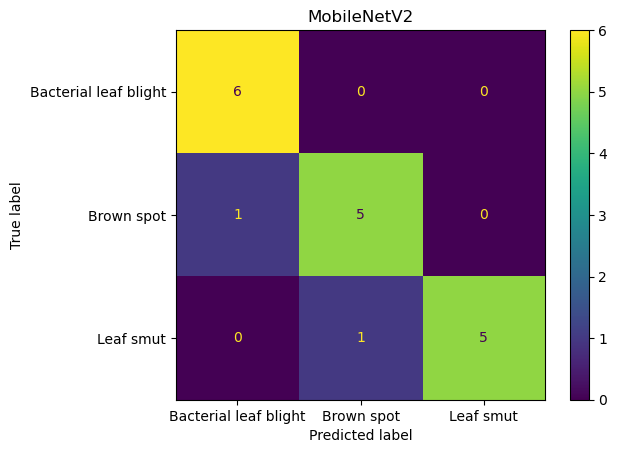

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step

===== Baseline CNN =====
                       precision    recall  f1-score   support

Bacterial leaf blight       0.38      0.50      0.43         6
           Brown spot       0.43      0.50      0.46         6
            Leaf smut       0.00      0.00      0.00         6

             accuracy                           0.33        18
            macro avg       0.27      0.33      0.30        18
         weighted avg       0.27      0.33      0.30        18



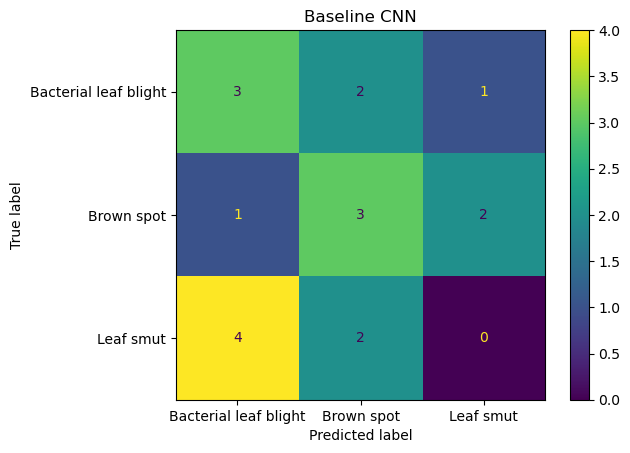

In [17]:
# Evaluate on test data:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

class_names = list(test_gen.class_indices.keys())
y_true = test_gen.classes

models_dict = {"MobileNetV2": mobilenet_model, "Baseline CNN": baseline_model}

for name, model in models_dict.items():
    y_pred = np.argmax(model.predict(test_gen), axis=1)
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=class_names))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot()
    plt.title(name); plt.show()

## Test Set Observations

- **MobileNetV2** classified 16 of 18 test images correctly. Every class has an F1 of 0.83 or higher.
- Errors: one Brown spot predicted as Bacterial leaf blight, and one Leaf smut predicted as Brown spot. This agrees with the EDA, where Brown spot and Leaf smut looked visually similar.
- **Baseline CNN** performed at chance level (33%) and never identified Leaf smut correctly (F1 = 0.00).

In [18]:
# Comparison table:


from sklearn.metrics import f1_score

train_eval_gen = eval_datagen.flow_from_dataframe(train_df, shuffle=False, **args)

results = []
for name, model in models_dict.items():
    y_pred = np.argmax(model.predict(test_gen), axis=1)
    results.append({
        "Model": name,
        "Train Acc": model.evaluate(train_eval_gen, verbose=0)[1],
        "Val Acc": model.evaluate(val_gen, verbose=0)[1],
        "Test Acc": model.evaluate(test_gen, verbose=0)[1],
        "Test Macro F1": f1_score(y_true, y_pred, average="macro"),
        "Parameters": model.count_params(),
    })

pd.DataFrame(results).round(3)

Found 83 validated image filenames belonging to 3 classes.
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step 


,Model,Train Acc,Val Acc,Test Acc,Test Macro F1,Parameters
0,MobileNetV2,0.940,0.833,0.889,0.889,2340163
1,Baseline CNN,0.602,0.556,0.333,0.297,101699


## Model Comparison Report

| Model | Train Acc | Val Acc | Test Acc | Test Macro F1 | Parameters |
|---|---|---|---|---|---|
| Baseline CNN (from scratch) | 0.602 | 0.556 | 0.333 | 0.297 | 101,699 |
| **MobileNetV2 (transfer learning)** | **0.940** | **0.833** | **0.889** | **0.889** | 2,340,163 (about 82K trainable) |

**Recommendation: MobileNetV2.** It is far more accurate, balanced across all three classes, and small enough to deploy in a web or mobile app. The baseline underfits because the dataset is too small to learn features from scratch.

**Caution:** the test set has only 18 images, so one wrong prediction changes accuracy by 5.6%. These numbers show a clear gap between the models, but the exact accuracy is approximate.

In [19]:
def train_mobilenet(datagen):
    gen = datagen.flow_from_dataframe(train_df, shuffle=True, seed=SEED, **args)
    b = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
    b.trainable = False
    m = models.Sequential([b, layers.GlobalAveragePooling2D(),
                           layers.Dense(64, activation="relu"), layers.Dropout(0.5),
                           layers.Dense(3, activation="softmax")])
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    m.fit(gen, validation_data=val_gen, epochs=30, callbacks=callbacks, verbose=0)
    return m.evaluate(val_gen, verbose=0)[1], m.evaluate(test_gen, verbose=0)[1]

aug_results = {"No augmentation": train_mobilenet(eval_datagen),
               "With augmentation": train_mobilenet(train_datagen)}
pd.DataFrame(aug_results, index=["Val Acc", "Test Acc"]).T.round(3)

Found 83 validated image filenames belonging to 3 classes.
Found 83 validated image filenames belonging to 3 classes.


,Val Acc,Test Acc
No augmentation,0.944,0.944
With augmentation,0.889,0.889


## Augmentation Experiment (Task 3)

| Setting | Val Acc | Test Acc |
|---|---|---|
| No augmentation | 0.944 | 0.944 |
| With augmentation | 0.889 | 0.889 |

The difference is a single image out of 18 (5.6%), so it is within noise and does not show that augmentation hurts. A likely reason it didn't help is that all images are lab-style photos with a plain black background, so the test images closely resemble the training images. Augmentation is expected to matter more for real field photos with varied angles, lighting and backgrounds. We keep augmentation in the final pipeline for robustness; confirming its benefit would need a larger, more varied test set or cross-validation.

## Challenges Faced

| Challenge | Technique used | Reason |
|---|---|---|
| Very small dataset (119 images) | Transfer learning (MobileNetV2) | Reuses features learned from ImageNet instead of learning from scratch |
| Overfitting risk | Frozen base, Dropout(0.5), EarlyStopping | Fewer trainable weights and regularisation |
| Duplicate image | Removed using file hashing | Prevents the same image appearing in both train and test sets |
| Unreliable evaluation on tiny data | Stratified 70/15/15 split with a separate test set | Equal classes in each set, and a test set never used for tuning |
| Evaluation contaminated by augmentation | Augment training data only | Validation and test must reflect real images |
| Pre-trained model expects specific input scaling | `preprocess_input` instead of `rescale=1/255` | Matches how MobileNetV2 was trained |
| Augmentation gain unclear | Compared with and without augmentation | Gain was inconclusive on 18 test images, kept for robustness |
| Reproducibility | Fixed seeds (Python, NumPy, TensorFlow) | Same split and results on rerun |

## Conclusion

- MobileNetV2 transfer learning reached **88.9% test accuracy (macro F1 0.89)**, against **33.3%** for a CNN trained from scratch. Transfer learning was essential for this small dataset.
- The model is balanced across the three diseases. Its few errors involve Brown spot and Leaf smut, which look visually similar.
- Augmentation had no measurable effect on this test set. It is kept for robustness.

**Limitations**
- Only 18 test images, so the accuracy estimate is uncertain.
- All images have a plain black background, so performance on real field photos is untested.
- No fine-tuning or hyperparameter search was done.

**Future work**
- Collect field images with varied backgrounds and lighting.
- Use cross-validation for a more reliable estimate.
- Fine-tune the top MobileNetV2 layers and tune dropout, dense units and learning rate.
- Add Grad-CAM to show which leaf regions drive each prediction.
- Deploy as a web or mobile app (Streamlit or TFLite).

In [20]:
import json
mobilenet_model.save("rice_leaf_model.keras")
json.dump(train_gen.class_indices, open("class_names.json", "w"))